# 1
## What does "training a model" actually mean?

Everyone says *"we trained the model"*. In this notebook we strip that idea down to the simplest model possible and see, with plain Python, what training really is.

**By the end you'll understand:**
1. How a model makes a prediction
2. What *loss* is and why we square the error
3. Why training = searching for the weights that make loss as small as possible

---
## 1. The model: a straight line

Our model takes an input `x` and makes a guess:

$$\hat{y} = w \cdot x + b$$

- `w` is the **weight**: how strongly the input affects the output
- `b` is the **bias**: a constant shift (we keep it at 0 for now; it gets its own post on Day 5)
- $\hat{y}$ (`y_pred`) is the model's **prediction**

`w` and `b` are the model's **parameters**. They are the only things the model can change. Learning means finding good values for them.

In [1]:
def predict(x, w, b=0):
    """A one-parameter linear model: y_pred = w * x + b"""
    return w * x + b

# One training example: input 3, correct answer 6
x = 3
y = 6

# Start with a random-ish guess for the weight
w = 0.5
print("Prediction:", predict(x, w))
print("Correct answer:", y)

Prediction: 1.5
Correct answer: 6


The model guessed **1.5**, but the right answer is **6**. It's clearly wrong, but *how* wrong? We need a single number that measures the mistake.

---
## 2. Loss: measuring how wrong the model is

We use the **squared error**:

$$\text{loss} = (\hat{y} - y)^2$$

**Why square it?**
- **Always positive**: guessing 2 too high and 2 too low are equally bad, and errors can't cancel out.
- **Punishes big mistakes more**: an error of 1 costs 1, but an error of 4 costs 16.
- **Smooth**: it's easy to take derivatives of, which matters a lot on Day 3 (gradient descent).

In [2]:
def squared_error(y_pred, y):
    """Loss for a single prediction"""
    return (y_pred - y) ** 2

y_pred = predict(x, w)
print(f"w = {w} -> y_pred = {y_pred}, loss = {squared_error(y_pred, y)}")

w = 0.5 -> y_pred = 1.5, loss = 20.25


---
## 3. Trying different weights

Now the key experiment: change `w` and watch what happens to the loss.

In [3]:
for w in [0.5, 0.6, 1.0, 2.0]:
    y_pred = predict(x, w)
    loss = squared_error(y_pred, y)
    print(f"w = {w:<4} -> y_pred = {y_pred:<4.1f} loss = {loss:.2f}")

w = 0.5  -> y_pred = 1.5  loss = 20.25
w = 0.6  -> y_pred = 1.8  loss = 17.64
w = 1.0  -> y_pred = 3.0  loss = 9.00
w = 2.0  -> y_pred = 6.0  loss = 0.00


As `w` moves closer to **2**, the prediction gets closer to 6 and the loss shrinks. At `w = 2` the prediction is perfect and the **loss is 0**.

What happens if we go *past* 2?

In [4]:
for w in [2.0, 2.5, 3.0, 4.0]:
    y_pred = predict(x, w)
    loss = squared_error(y_pred, y)
    print(f"w = {w:<4} -> y_pred = {y_pred:<4.1f} loss = {loss:.2f}")

w = 2.0  -> y_pred = 6.0  loss = 0.00
w = 2.5  -> y_pred = 7.5  loss = 2.25
w = 3.0  -> y_pred = 9.0  loss = 9.00
w = 4.0  -> y_pred = 12.0 loss = 36.00


Overshooting is penalised too. The loss rises again. So there's a **single best value** of `w`, and the loss gets worse the further we move away from it in either direction.

---
## 4. Sneak peek: the shape of the loss

Instead of testing a handful of weights, let's compute the loss for *hundreds* of them and plot it. (Day 2 is all about this curve.)

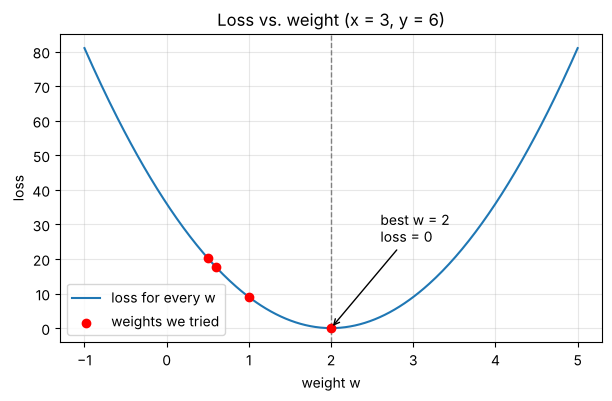

In [5]:
import numpy as np
import matplotlib.pyplot as plt

ws = np.linspace(-1, 5, 300)
losses = (ws * x - y) ** 2

tried = np.array([0.5, 0.6, 1.0, 2.0])
tried_losses = (tried * x - y) ** 2

plt.figure(figsize=(7, 4))
plt.plot(ws, losses, label="loss for every w")
plt.scatter(tried, tried_losses, color="red", zorder=3, label="weights we tried")
plt.axvline(2, linestyle="--", color="gray", linewidth=1)
plt.annotate("best w = 2\nloss = 0", xy=(2, 0), xytext=(2.6, 25),
             arrowprops=dict(arrowstyle="->"))
plt.xlabel("weight w")
plt.ylabel("loss")
plt.title("Loss vs. weight (x = 3, y = 6)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A **U-shaped curve** (a parabola), with its lowest point exactly at `w = 2`.

This picture is the whole game: **training a model means finding the bottom of this curve.**

---
## 5. Key takeaways

| Concept | Meaning |
|---|---|
| **Model** | A formula that turns inputs into a prediction: `w * x + b` |
| **Parameters** | The knobs the model can turn (`w`, `b`) |
| **Loss** | One number saying how wrong the prediction is |
| **Training** | Adjusting the parameters to make the loss as small as possible |

Every neural network, even ones with billions of parameters, does a scaled-up version of exactly this.

### Try it yourself
1. Change the example to `x = 4, y = 10`. What's the best `w` now? Check with the plot.
2. Replace squared error with absolute error `abs(y_pred - y)`. How does the curve's shape change?
3. Can you write a loop that tries `w` from 0 to 4 in steps of 0.1 and prints the one with the smallest loss?

---
